# Delta hedging a European call — demonstration notebook
MAC F244 project (topic 12). This notebook runs in about a minute on a laptop. It walks through the
mathematics → code correspondence and reproduces small versions of each experiment.
The full results (40,000 paths) are produced by `python scripts/run_experiments.py --mode full`
and are loaded at the end.

**Measures.** Paths for hedging experiments are simulated under the *physical* measure **P**
(drift μ). Prices and deltas use Black–Scholes (risk-neutral **Q**) formulas. The pricing check
in §1 simulates under **Q** (drift r).

In [1]:
import sys, numpy as np, pandas as pd
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from hedging import *
pd.set_option("display.width", 140, "display.precision", 4)
S0, K, T, r, sigma, mu = 100.0, 100.0, 0.25, 0.05, 0.20, 0.10
print("BS call price C0 =", round(float(call_price(S0, K, T, r, sigma)), 4),
      "| delta0 =", round(float(call_delta(S0, K, T, r, sigma)), 4),
      "| vega =", round(float(vega(S0, K, T, r, sigma)), 4))

BS call price C0 = 4.615 | delta0 = 0.5695 | vega = 19.644


## 1. Pricing checks
Put–call parity $C-P=S-Ke^{-r\tau}$, delta vs finite difference, and Monte Carlo under **Q** vs **P**.

In [2]:
S = np.linspace(60, 140, 9)
parity = call_price(S, K, T, r, sigma) - put_price(S, K, T, r, sigma) - (S - K*np.exp(-r*T))
fd = (call_price(S+1e-4, K, T, r, sigma) - call_price(S-1e-4, K, T, r, sigma)) / 2e-4
print("max parity error:", np.abs(parity).max(), "| max delta FD error:", np.abs(fd - call_delta(S, K, T, r, sigma)).max())
rng = np.random.default_rng(1)
for m, label in [(r, "Q (drift r)"), (mu, "P (drift mu)")]:
    ST = simulate_gbm(S0, m, sigma, T, 1, 1_000_000, rng)[:, -1]
    x = np.exp(-r*T) * np.maximum(ST - K, 0)
    se = x.std() / np.sqrt(len(x))
    z = (x.mean() - call_price(S0, K, T, r, sigma)) / se
    print(f"{label:13s} discounted mean payoff = {x.mean():.4f} (SE {se:.4f}), z vs BS = {z:+.2f}")

max parity error: 1.4210854715202004e-14 | max delta FD error: 1.5126855323899235e-10
Q (drift r)   discounted mean payoff = 4.6039 (SE 0.0066), z vs BS = -1.68
P (drift mu)  discounted mean payoff = 5.3706 (SE 0.0071), z vs BS = +106.53


Read the z-scores: under **Q** a value with |z| below about 3 is consistent with the BS price (note that any
single 95% interval misses 1 time in 20, so an occasional |z| near 2–2.5 is expected). Under **P** the
z-score is far outside that range: pricing requires the risk-neutral measure even though hedging P&L is
realised under **P**.

## 2. Hedge accounting on a path you can check by hand
Four rebalances (Δt = 1/16 year). Columns: delta held after trading, trade (shares), cash paid for the trade,
interest earned since the last date, transaction cost, option payoff, and cash after all of that.

In [3]:
from hedging.validation import manual_example
path, p = manual_example()
led = hedge_ledger(path, p["K"], p["T"], p["r"], p["sigma"], cost=0.0)
print("premium received:", round(led.attrs["premium"], 6), "| terminal P&L:", round(led.attrs["pnl"], 6))
led.round(4)

premium received: 4.614997 | terminal P&L: 1.349376


,k,t,S,delta,trade,trade_cash,interest,tcost,payoff,cash_after
0,0,0.0000,100.0,0.5695,0.5695,-56.9460,0.0000,0.0,0.0,-52.3310
1,1,0.0625,103.0,0.6889,0.1195,-12.3072,-0.1638,0.0,0.0,-64.8020
2,2,0.1250,98.0,0.4357,-0.2533,24.8216,-0.2028,0.0,0.0,-40.1833
3,3,0.1875,101.0,0.6128,0.1771,-17.8859,-0.1258,0.0,0.0,-58.1950
4,4,0.2500,104.0,0.0000,-0.6128,63.7265,-0.1821,0.0,4.0,1.3494


In [4]:
# The same number from an independent formula: premium grown at r + discounted stock gains − payoff
print(pnl_gains_form(path[None, :], p["K"], p["T"], p["r"], p["sigma"])[0])

1.3493763675535106


## 3. Experiment A (small): rebalancing frequency on shared paths

In [5]:
rng = np.random.default_rng(2026)
P = simulate_gbm(S0, mu, sigma, T, 252, 5000, rng)
rows = []
for N in [3, 9, 21, 63, 126, 252]:
    out = hedge_short_call(P, K, T, r, sigma, step=252 // N)
    s = summarize(out["pnl"]); s["N"] = N
    s["kamal_derman"] = np.sqrt(np.pi/4) * vega(S0, K, T, r, sigma) * sigma / np.sqrt(N)
    rows.append(s)
A = pd.DataFrame(rows)[["N", "mean", "se_mean", "std", "se_std", "kamal_derman", "q05", "es05"]]
print("log-log slope of std vs N:", round(loglog_slope(A.N, A["std"]), 3), "(theory −0.5)")
A

log-log slope of std vs N: -0.477 (theory −0.5)


,N,mean,se_mean,std,se_std,kamal_derman,q05,es05
0,3,0.0064,0.0258,1.8232,0.0225,2.0102,-3.1467,-4.4286
1,9,0.0043,0.0157,1.1079,0.0148,1.1606,-1.8220,-2.5947
2,21,-0.0079,0.0105,0.7412,0.0102,0.7598,-1.2263,-1.7606
3,63,0.0043,0.0061,0.4341,0.0058,0.4387,-0.7230,-1.0135
4,126,-0.0014,0.0044,0.3105,0.0041,0.3102,-0.5184,-0.7200
5,252,-0.0031,0.0031,0.2222,0.0033,0.2193,-0.3608,-0.5189


## 4. Experiment B (small): hedging with the wrong volatility
Premium and delta both use σ_h; the true σ is 20%. The theory column is the gamma-weighted variance gap.

In [6]:
rows = []
for sh in [0.15, 0.20, 0.25]:
    out = hedge_short_call(P, K, T, r, sh, step=1)
    pred = predicted_pnl_misspecified(P, K, T, r, sigma, sh)
    rows.append(dict(sigma_h=sh, mean=out["pnl"].mean(), std=out["pnl"].std(), theory_mean=pred.mean()))
pd.DataFrame(rows)

,sigma_h,mean,std,theory_mean
0,0.15,-0.9894,0.4925,-0.9860
1,0.20,-0.0031,0.2222,0.0000
2,0.25,0.9889,0.3961,0.9912


## 5. Experiment C (small): costs make more trading worse beyond a point
P&L is linear in the cost rate: $\text{PnL}(c)=\text{PnL}(0)-c\cdot TV$, so one simulation serves every c.

In [7]:
rows = []
for N in [3, 9, 21, 63, 126, 252]:
    out = hedge_short_call(P, K, T, r, sigma, step=252 // N)
    for c in [0, 0.001, 0.005]:
        x = out["pnl"] - c * out["traded_value_fv"]
        rows.append(dict(N=N, cost_bp=c*1e4, mean=x.mean(), rmse=np.sqrt(np.mean(x**2))))
pd.DataFrame(rows).pivot(index="N", columns="cost_bp", values="rmse").round(3)

cost_bp,0.0,10.0,50.0
N,,,
3,1.823,1.841,2.047
9,1.108,1.141,1.585
21,0.741,0.803,1.575
63,0.434,0.585,1.971
126,0.310,0.591,2.498
252,0.222,0.695,3.267


## 6. Full-mode results (40,000 paths) and figures
Produced by `scripts/run_experiments.py --mode full`; loaded here, not recomputed.

In [8]:
full = ROOT / "results" / "full" / "tables"
if full.exists():
    display(pd.read_csv(full / "A_frequency.csv")[["N", "mean", "se_mean", "std", "se_std", "rmse", "q05", "es05", "kamal_derman_std"]])
    display(pd.read_csv(full / "C_best_frequency.csv"))
else:
    print("Run: python scripts/run_experiments.py --mode full")

,N,mean,se_mean,std,se_std,rmse,q05,es05,kamal_derman_std
0,3,-2.1777e-02,0.0093,1.8555,0.0088,1.8556,-3.2333,-4.5704,2.0102
1,9,-4.0953e-03,0.0055,1.1007,0.0051,1.1007,-1.8421,-2.6173,1.1606
2,21,-5.4443e-05,0.0037,0.7408,0.0035,0.7408,-1.2151,-1.7348,0.7598
3,63,2.5010e-04,0.0022,0.4341,0.0021,0.4341,-0.7127,-1.0054,0.4387
4,126,4.5683e-04,0.0015,0.3077,0.0015,0.3077,-0.5025,-0.7065,0.3102
5,252,2.0806e-04,0.0011,0.2164,0.0010,0.2164,-0.3553,-0.4922,0.2193
6,630,-3.5284e-04,0.0007,0.1386,0.0007,0.1386,-0.2249,-0.3125,0.1387
7,1260,-7.4452e-06,0.0005,0.0979,0.0005,0.0979,-0.1615,-0.2223,0.0981


,cost,N_min_rmse,interval_days,rmse,mean,std,mean_cost_fv
0,0.0000,1260,0.05,0.0979,-7.4452e-06,0.0979,0.0000
1,0.0005,252,0.25,0.3916,-3.0916e-01,0.2403,0.3094
2,0.0010,126,0.50,0.5842,-4.7171e-01,0.3447,0.4722
3,0.0020,63,1.00,0.8875,-7.3621e-01,0.4957,0.7365
4,0.0050,21,3.00,1.5602,-1.3034e+00,0.8575,1.3034


fig1_frequency.png


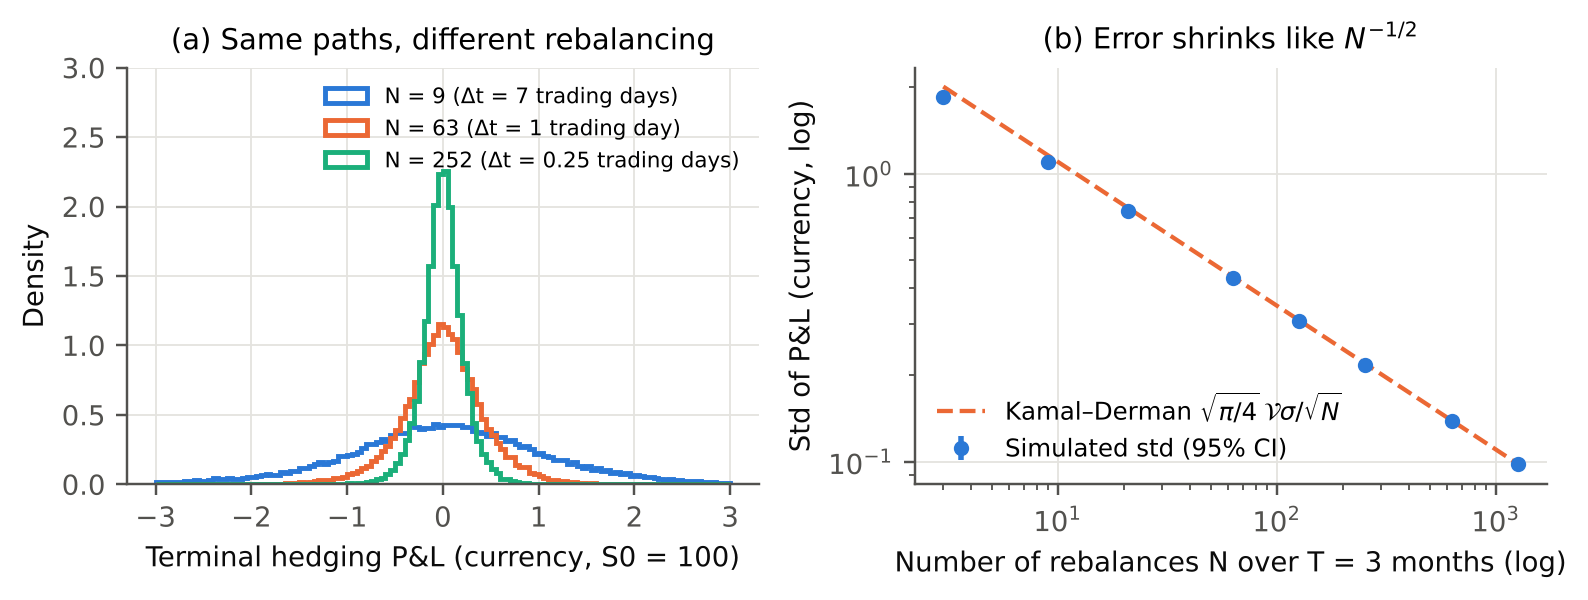

fig2_misspecification.png


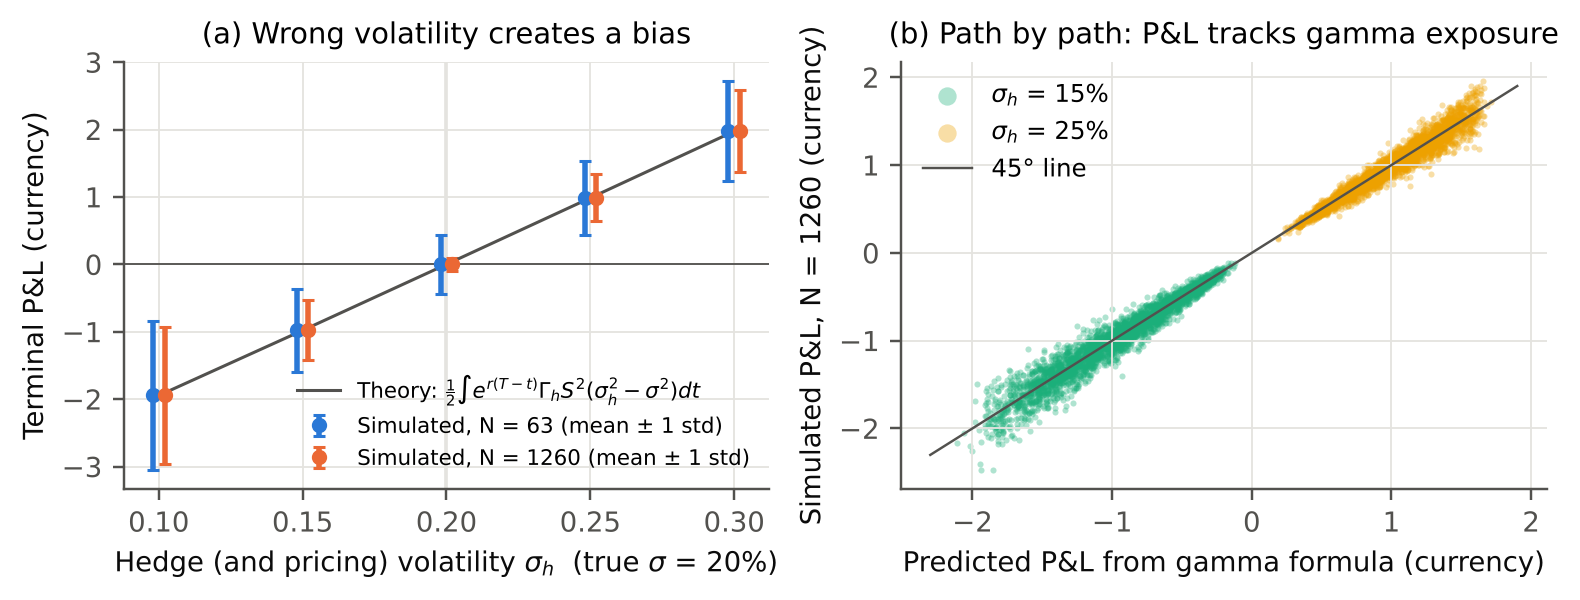

fig3_costs.png


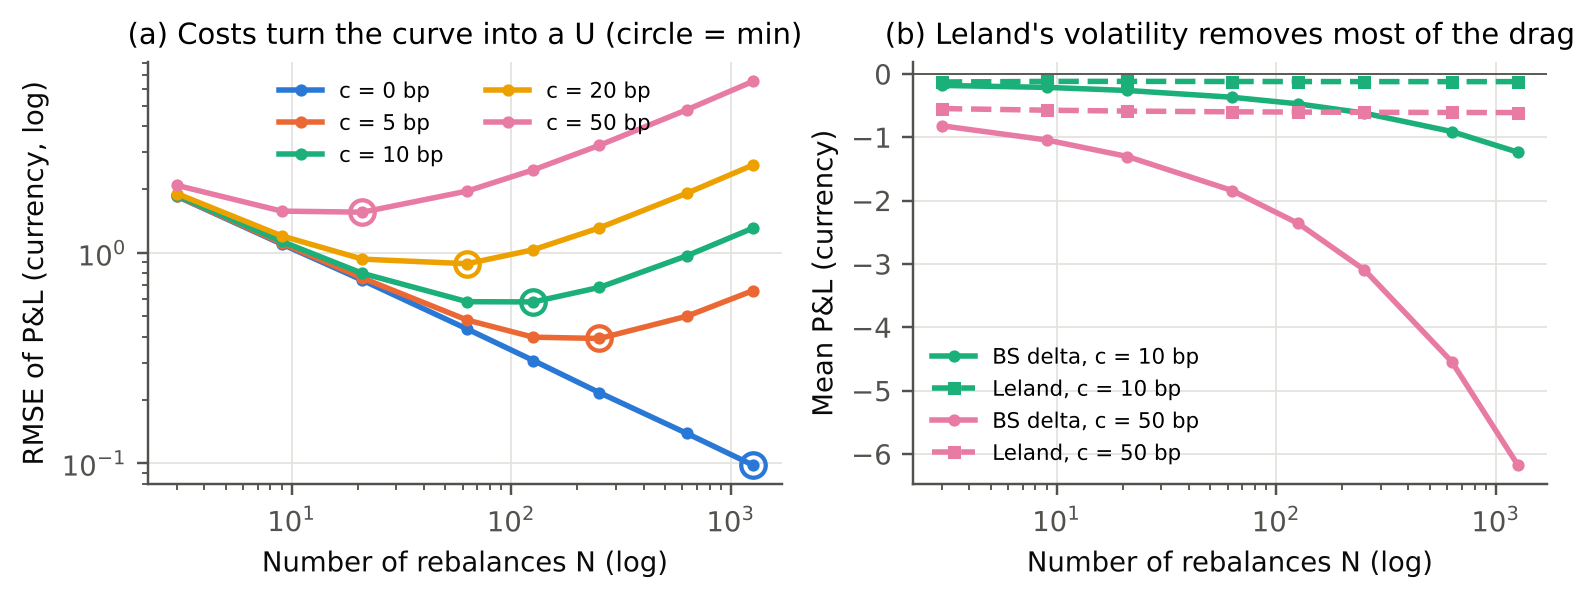

fig4_regimes.png


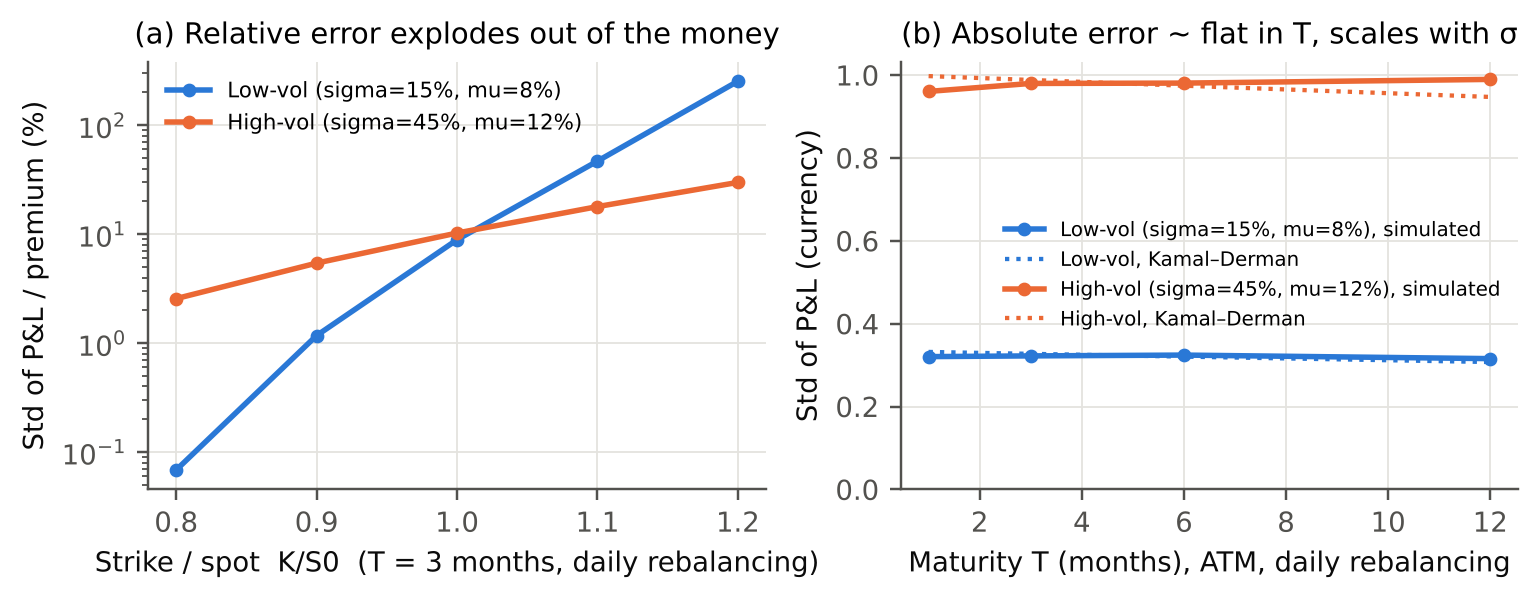

fig5_realdata.png


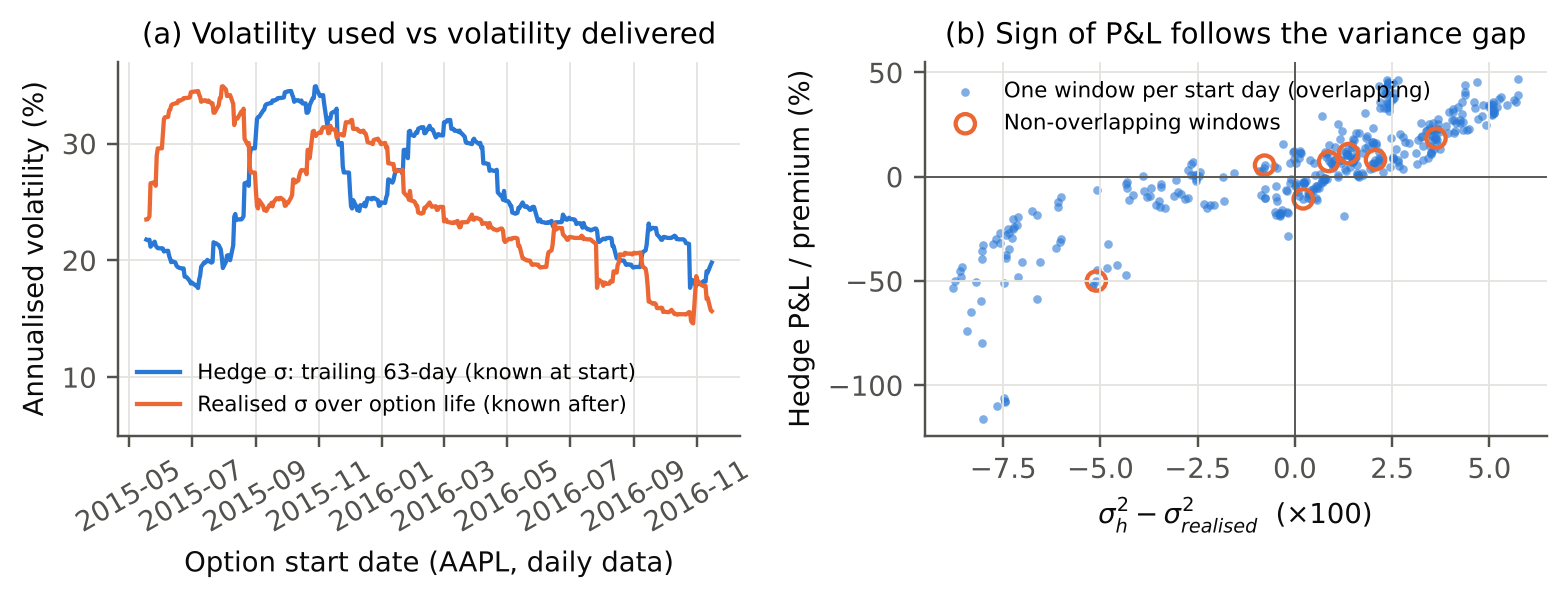

In [9]:
from IPython.display import Image, display
figdir = ROOT / "results" / "full" / "figures"
for f in sorted(figdir.glob("fig*.png")):
    print(f.name); display(Image(filename=str(f), width=760))

### What these plots can and cannot show
* They show behaviour **inside the Black–Scholes world** (constant σ, no jumps, continuous prices) except
  §E, which uses one historical AAPL path segment with *model* premiums (no market option quotes).
* Monte Carlo standard errors quantify sampling noise only, not model error.
* Finite-sample statistics need not be monotone in N (e.g. |mean| is not); see `A_monotonicity.csv`.